In [313]:
import pandas as pd
import numpy as np
import seaborn as sns
df=pd.read_csv('weather/Rainfall.csv')
print(df.shape)
df.tail()

(366, 12)


,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
361,27,1022.7,18.8,17.7,16.9,15.0,84,90,yes,0.0,30.0,18.4
362,28,1026.6,18.6,17.3,16.3,12.8,75,85,yes,1.0,20.0,25.9
363,29,1025.9,18.9,17.7,16.4,13.3,75,78,yes,4.6,70.0,33.4
364,30,1025.3,19.2,17.3,15.2,13.3,78,86,yes,1.2,20.0,20.9
365,31,1026.4,20.5,17.8,15.5,13.0,74,66,no,5.7,20.0,23.3


In [314]:
df.isnull().sum()

day                       0
pressure                  0
maxtemp                   0
temparature               0
mintemp                   0
dewpoint                  0
humidity                  0
cloud                     0
rainfall                  0
sunshine                  0
         winddirection    1
windspeed                 1
dtype: int64

In [315]:
df.rename(str.strip,axis=1,inplace=True)
for col in df.columns:
    if df[col].isnull().sum()>0:
        val=df[col].mean()
        df[col]=df[col].fillna(val)
# fill in na with mean 

In [316]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   day            366 non-null    int64  
 1   pressure       366 non-null    float64
 2   maxtemp        366 non-null    float64
 3   temparature    366 non-null    float64
 4   mintemp        366 non-null    float64
 5   dewpoint       366 non-null    float64
 6   humidity       366 non-null    int64  
 7   cloud          366 non-null    int64  
 8   rainfall       366 non-null    str    
 9   sunshine       366 non-null    float64
 10  winddirection  366 non-null    float64
 11  windspeed      366 non-null    float64
dtypes: float64(8), int64(3), str(1)
memory usage: 34.4 KB


In [317]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
day,366.0,15.756831,8.823592,1.0,8.000,16.00,23.000,31.0
pressure,366.0,1013.742623,6.414776,998.5,1008.500,1013.00,1018.100,1034.6
maxtemp,366.0,26.191257,5.978343,7.1,21.200,27.75,31.200,36.3
temparature,366.0,23.747268,5.632813,4.9,18.825,25.45,28.600,32.4
mintemp,366.0,21.894536,5.594153,3.1,17.125,23.70,26.575,30.0
dewpoint,366.0,19.989071,5.997021,-0.4,16.125,21.95,25.000,26.7
humidity,366.0,80.177596,10.062470,36.0,75.000,80.50,87.000,98.0
cloud,366.0,71.128415,21.798012,0.0,58.000,80.00,88.000,100.0
sunshine,366.0,4.419399,3.934398,0.0,0.500,3.50,8.200,12.1
winddirection,366.0,101.506849,81.611697,10.0,40.000,70.00,190.000,350.0


rainfall
yes    249
no     117
Name: count, dtype: int64


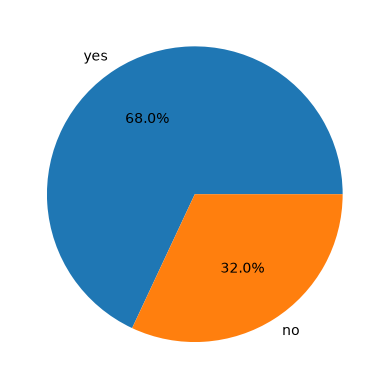

In [318]:
import matplotlib.pyplot as plt
rainfall=df['rainfall'].value_counts()
print(rainfall)
plt.pie(rainfall.values,labels=rainfall.index,autopct='%1.1f%%')

In [319]:
df.groupby('rainfall').mean()

,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,sunshine,winddirection,windspeed
rainfall,,,,,,,,,,,
no,15.623932,1014.576923,27.070940,24.053846,21.957265,18.766667,73.000000,51.256410,7.586325,103.076923,19.275214
yes,15.819277,1013.350602,25.777912,23.603213,21.865060,20.563454,83.550201,80.465863,2.931325,100.769104,22.599747


In [320]:
def correlation_ratio(categories,values):
    categories=np.asarray(categories)
    values=np.asarray(values,dtype=float)
    grand_mean=values.mean()
    ss_between=sum(
        (categories==c).sum()*(values[categories==c].mean()-grand_mean)**2
        for c in np.unique(categories)
    )
    ss_total=((values-grand_mean)**2).sum()
    return np.sqrt(ss_between/ss_total)
rows=[]
import scipy.stats as stats
num_features=[c for c in df.select_dtypes('number').columns]
for col in num_features:
    a=df[df['rainfall']=='yes'][col]
    b=df[df['rainfall']=='no'][col]
    t,p_t=stats.ttest_ind(a,b,equal_var=False)
    eta=correlation_ratio(df['rainfall'],df[col])
    rows.append({
        'feature':col,
        't_p':p_t,
        'eta_square':eta**2,
    })
tests=pd.DataFrame(rows).set_index('feature')
m=len(tests) # rows of df
tests['t_p_bonf']=(tests['t_p']*m).clip(upper=1) # remove errors from parallel calculation 
alpha=0.05
tests['related_t_test']=tests['t_p_bonf']<alpha
tests['eta_test']=tests['eta_square']>0.14
tests.sort_values('eta_test',ascending=True)
# according to t-test and eta(effect size) test---> correlated features are humidity, cloud, sunshine (windspeed)


,t_p,eta_square,t_p_bonf,related_t_test,eta_test
feature,,,,,
day,8.477787e-01,0.000107,1.000000e+00,False,False
pressure,1.031529e-01,0.007970,1.000000e+00,False,False
maxtemp,5.629701e-02,0.010202,6.192671e-01,False,False
temparature,4.887609e-01,0.001396,1.000000e+00,False,False
mintemp,8.884188e-01,0.000059,1.000000e+00,False,False
dewpoint,1.425267e-02,0.019576,1.567794e-01,False,False
winddirection,8.090691e-01,0.000174,1.000000e+00,False,False
windspeed,3.112871e-03,0.023836,3.424158e-02,True,False
humidity,8.561733e-18,0.239731,9.417906e-17,True,True


<Axes: >

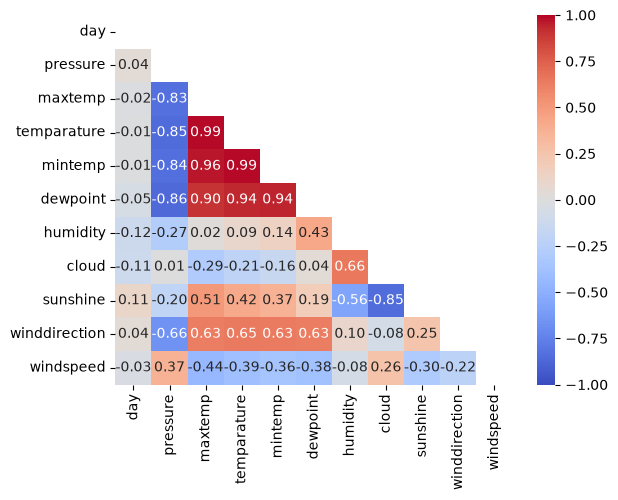

In [321]:
X=df.drop('rainfall',axis=1)
corr_matrix=X.corr()

mask=np.triu(np.ones_like(corr_matrix,dtype=bool))

sns.heatmap(corr_matrix,mask=mask,annot=True,fmt='.2f',cmap='coolwarm',vmin=-1,vmax=1)

In [322]:
feature=tests[tests['eta_test']].index
all_feature=tests.index
# same as eature=tests[tests['eta_test']==True].index---> use True instead of 'True', since it is boolean type rather than string type
print(feature)
print(all_feature)

Index(['humidity', 'cloud', 'sunshine'], dtype='str', name='feature')
Index(['day', 'pressure', 'maxtemp', 'temparature', 'mintemp', 'dewpoint',
       'humidity', 'cloud', 'sunshine', 'winddirection', 'windspeed'],
      dtype='str', name='feature')


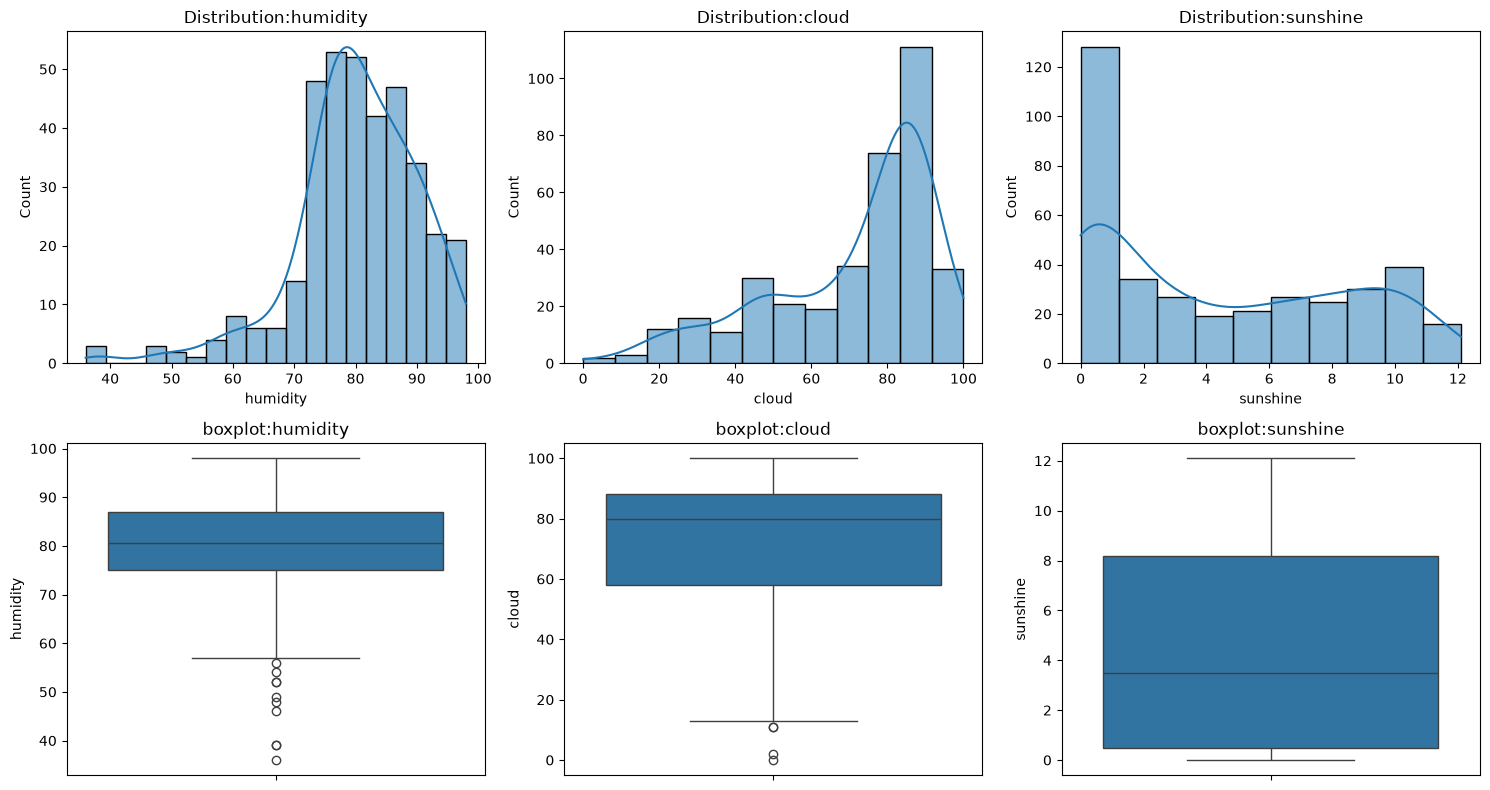

In [323]:
fig,axes=plt.subplots(2,len(feature),figsize=(15,8))
for i,col in enumerate(feature):
# i col
# 0 humidity
# 1 cloud
# 2 sunshine
    sns.histplot(df[col],kde=True, ax=axes[0,i])
    axes[0,i].set_title(f'Distribution:{col}')
    sns.boxplot(df[col],ax=axes[1,i])
    axes[1,i].set_title(f'boxplot:{col}')
plt.tight_layout()
# imbalanced data 

In [324]:
X=df[feature]
target=df.rainfall
target=target.astype('category')
mapping={val:i for i,val in enumerate (target.cat.categories)}
target=target.cat.codes
print(mapping)
target.tail()

{'no': 0, 'yes': 1}


361    1
362    1
363    1
364    1
365    0
dtype: int8

xgb:ROC-AUC score:0.7617
              precision    recall  f1-score   support

           0       0.65      0.46      0.54        24
           1       0.77      0.88      0.82        50

    accuracy                           0.74        74
   macro avg       0.71      0.67      0.68        74
weighted avg       0.73      0.74      0.73        74

LogReg:ROC-AUC score:0.8833
              precision    recall  f1-score   support

           0       0.81      0.54      0.65        24
           1       0.81      0.94      0.87        50

    accuracy                           0.81        74
   macro avg       0.81      0.74      0.76        74
weighted avg       0.81      0.81      0.80        74

SVC:ROC-AUC score:0.8375
              precision    recall  f1-score   support

           0       0.80      0.50      0.62        24
           1       0.80      0.94      0.86        50

    accuracy                           0.80        74
   macro avg       0.80      0.72      0.74       

/Users/xiaoying/Desktop/machinelearning/machinelearning/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


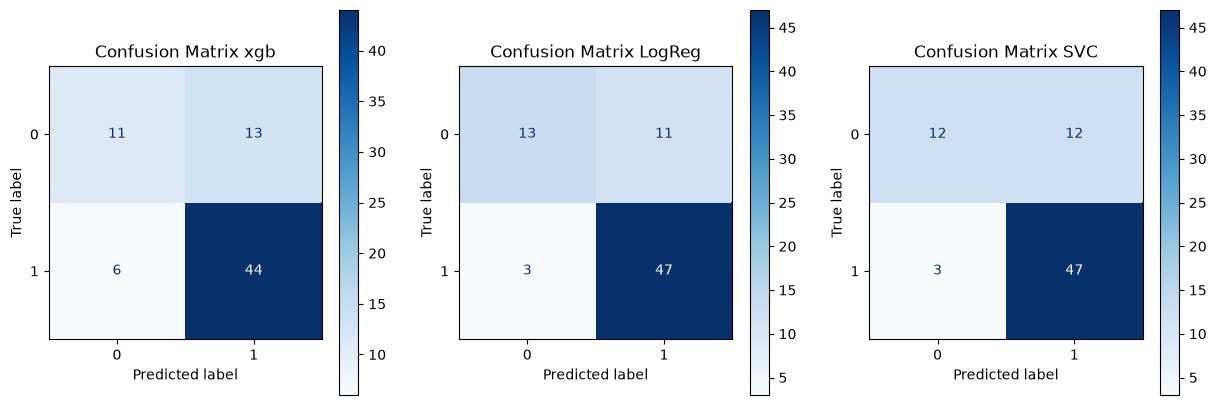

In [325]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,target,test_size=0.2,stratify=target,random_state=2)

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay

scaler=StandardScaler()
models={
    'xgb':XGBClassifier(),
    'LogReg':LogisticRegression(max_iter=1000),
    'SVC':SVC(kernel='rbf',probability=True),
}
fig,axes=plt.subplots(1,len(models),figsize=(15,5))
for i,(mname,model) in enumerate(models.items()):
    pipe=make_pipeline(scaler,model)
    pipe.fit(X_train,y_train)
    y_pred_proba=pipe.predict_proba(X_test)[:,1]
    y_pred=pipe.predict(X_test)
    # should be a 1d array, got an array
    # y_pred_proba return an array with probability of each category
    # Column 0: The predicted probability that the sample belongs to class 0 (e.g., probability of no rain).
    # Column 1: The predicted probability that the sample belongs to class 1 (e.g., probability of rain).
    score=metrics.roc_auc_score(y_test,y_pred_proba)
    print(f"{mname}:ROC-AUC score:{score:.4f}")
    print(metrics.classification_report(y_test,y_pred))

    ConfusionMatrixDisplay.from_estimator(pipe,X_test,y_test,ax=axes[i],cmap='Blues')
    axes[i].set_title(f"Confusion Matrix {mname}")